# Carga de Datos

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("deepcontractor/car-price-prediction-challenge")

print("Path to dataset files:", path)

100%|██████████| 429k/429k [00:00<00:00, 82.4MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/deepcontractor/car-price-prediction-challenge/versions/1


In [3]:
df = pd.read_csv(path + "/car_price_prediction.csv")
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [ ]:
#Nrmalizamos los nombres de las columnas
df.columns = df.columns.str.lower().str.replace(" ", "_")
df.columns
pd.set_option("display.float_format", "{:.6f}".format)

In [5]:
#Normalizamos los datos de los tipo strings
string_columns = list(df.select_dtypes(include="object").columns)
for col in string_columns:
    df[col] = df[col].str.lower().str.replace(" ", "_")

In [ ]:
df.head()

,id,price,levy,manufacturer,model,prod._year,category,leather_interior,fuel_type,engine_volume,mileage,cylinders,gear_box_type,drive_wheels,doors,wheel,color,airbags
0,45654403,13328,1399,lexus,rx_450,2010,jeep,yes,hybrid,3.5,186005_km,6.000000,automatic,4x4,04-may,left_wheel,silver,12
1,44731507,16621,1018,chevrolet,equinox,2011,jeep,no,petrol,3,192000_km,6.000000,tiptronic,4x4,04-may,left_wheel,black,8
2,45774419,8467,-,honda,fit,2006,hatchback,no,petrol,1.3,200000_km,4.000000,variator,front,04-may,right-hand_drive,black,2
3,45769185,3607,862,ford,escape,2011,jeep,yes,hybrid,2.5,168966_km,4.000000,automatic,4x4,04-may,left_wheel,white,0
4,45809263,11726,446,honda,fit,2014,hatchback,yes,petrol,1.3,91901_km,4.000000,automatic,front,04-may,left_wheel,silver,4


# Exploratory Data Analysis
- Check missing values
- Check Duplicates
- Check data types
- Check the number of unique values of each column
- Check statistics of the dataset


In [7]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

Filas: 19237
Columnas: 18


In [ ]:
#Missing values
nulos = (
    df.isnull()
    .sum()
    .to_frame("cantidad_nulos")
)
nulos.sort_values(by="cantidad_nulos", ascending=False)

,cantidad_nulos
id,0
price,0
levy,0
manufacturer,0
model,0
prod._year,0
category,0
leather_interior,0
fuel_type,0
engine_volume,0


NO missing values


In [9]:
for col in df.columns:
    print(col)
    print(df[col].unique())
    print()

id
[45654403 44731507 45774419 ... 45804997 45793526 45813273]

price
[13328 16621  8467 ... 56814 63886 22075]

levy
['1399' '1018' '-' '862' '446' '891' '761' '751' '394' '1053' '1055'
 '1079' '810' '2386' '1850' '531' '586' '1249' '2455' '583' '1537' '1288'
 '915' '1750' '707' '1077' '1486' '1091' '650' '382' '1436' '1194' '503'
 '1017' '1104' '639' '629' '919' '781' '530' '640' '765' '777' '779' '934'
 '769' '645' '1185' '1324' '830' '1187' '1111' '760' '642' '1604' '1095'
 '966' '473' '1138' '1811' '988' '917' '1156' '687' '11714' '836' '1347'
 '2866' '1646' '259' '609' '697' '585' '475' '690' '308' '1823' '1361'
 '1273' '924' '584' '2078' '831' '1172' '893' '1872' '1885' '1266' '447'
 '2148' '1730' '730' '289' '502' '333' '1325' '247' '879' '1342' '1327'
 '1598' '1514' '1058' '738' '1935' '481' '1522' '1282' '456' '880' '900'
 '798' '1277' '442' '1051' '790' '1292' '1047' '528' '1211' '1493' '1793'
 '574' '930' '1998' '271' '706' '1481' '1677' '1661' '1286' '1408' '1090'
 '595' '

In [ ]:
#we drop the rows with missing values in the levy column
df["levy"] = df["levy"].replace("-",np.nan)
df = df.dropna(subset=["levy"])
df["levy"] = df["levy"].astype(float)


In [11]:
#change to dummies the leather interior column
df["leather_interior"] = df["leather_interior"].replace({"yes": 1, "no": 0})

/tmp/ipykernel_1593/1976443066.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["leather_interior"] = df["leather_interior"].replace({"yes": 1, "no": 0})


In [ ]:
#Engine volume column, we will convert it to numeric
df["turbo"] = df["engine_volume"].str.contains("turbo", case=False, na=False).astype(int)
df["engine_volume"] = df["engine_volume"].str.replace("_turbo", "", case=False).astype(float)

In [ ]:
#mileage column, we will convert it to numeric
df["mileage"] = df["mileage"].str.replace("_km", "", case=False).astype(float)

In [ ]:
# Doors column
df["doors"] = df["doors"].replace({"04-may":"04-05","02-mar":"02-03"})

In [15]:
#Checking duplicates
duplicates = df.duplicated()
print("Number of duplicates:", duplicates.sum())

Number of duplicates: 203


In [16]:
#show the duplicates and order
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))


,id,price,levy,manufacturer,model,prod._year,category,leather_interior,fuel_type,engine_volume,mileage,cylinders,gear_box_type,drive_wheels,doors,wheel,color,airbags,turbo
5754,35464629,7840,1111.000000,honda,fit,2012,hatchback,0,petrol,1.300000,108000.000000,4.000000,automatic,front,04-05,right-hand_drive,blue,6,0
7269,35464629,7840,1111.000000,honda,fit,2012,hatchback,0,petrol,1.300000,108000.000000,4.000000,automatic,front,04-05,right-hand_drive,blue,6,0
8158,42412373,15367,781.000000,chevrolet,trax,2018,jeep,1,petrol,1.400000,1405.000000,4.000000,automatic,4x4,04-05,left_wheel,black,8,0
9275,42412373,15367,781.000000,chevrolet,trax,2018,jeep,1,petrol,1.400000,1405.000000,4.000000,automatic,4x4,04-05,left_wheel,black,8,0
10756,43642888,26343,934.000000,toyota,camry_se,2015,sedan,1,petrol,2.500000,47128.000000,4.000000,automatic,front,04-05,left_wheel,black,8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18757,45815551,11290,642.000000,volkswagen,passat,2012,sedan,1,diesel,2.000000,97070.000000,4.000000,tiptronic,front,04-05,left_wheel,grey,12,1
3756,45815994,4077,751.000000,hyundai,sonata,2013,sedan,1,petrol,2.400000,111930.000000,4.000000,automatic,front,04-05,left_wheel,silver,12,0
14469,45815994,4077,751.000000,hyundai,sonata,2013,sedan,1,petrol,2.400000,111930.000000,4.000000,automatic,front,04-05,left_wheel,silver,12,0
1171,45816384,49237,730.000000,hyundai,tucson,2016,jeep,1,petrol,1.600000,27000.000000,4.000000,tiptronic,4x4,04-05,left_wheel,white,12,0


In [17]:
#Drop duplicates
df = df.drop_duplicates()
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

Filas: 13215
Columnas: 19


In [ ]:
#Checking the data types of the columns
df.dtypes

,0
id,int64
price,int64
levy,float64
manufacturer,object
model,object
prod._year,int64
category,object
leather_interior,int64
fuel_type,object
engine_volume,float64


# Descriptive Statistics

## Univariate Analysis

### Numerical Features

In [19]:
df[["price", "levy", "prod._year","engine_volume", "mileage", "cylinders","airbags"]].describe().T

,count,mean,std,min,25%,50%,75%,max
price,13215.000000,17326.159364,19352.082456,1.000000,3763.000000,13589.000000,23521.000000,872946.000000
levy,13215.000000,906.299205,463.296871,87.000000,640.000000,781.000000,1058.000000,11714.000000
prod._year,13215.000000,2013.133560,3.053819,1965.000000,2011.000000,2013.000000,2015.000000,2020.000000
engine_volume,13215.000000,2.315437,0.873008,0.000000,1.800000,2.000000,2.500000,20.000000
mileage,13215.000000,376203.388120,20605010.146942,0.000000,68000.000000,118462.000000,179381.000000,2147483647.000000
cylinders,13215.000000,4.513810,1.123359,1.000000,4.000000,4.000000,4.000000,16.000000
airbags,13215.000000,6.874082,4.465586,0.000000,4.000000,4.000000,12.000000,16.000000


we have to check the price, there are many outliers (min and max) also engine_volume can't be 0

In [ ]:
#histograms for numeric columns
num_features = ["price", "levy", "prod._year","engine_volume", "mileage", "cylinders","airbags"]


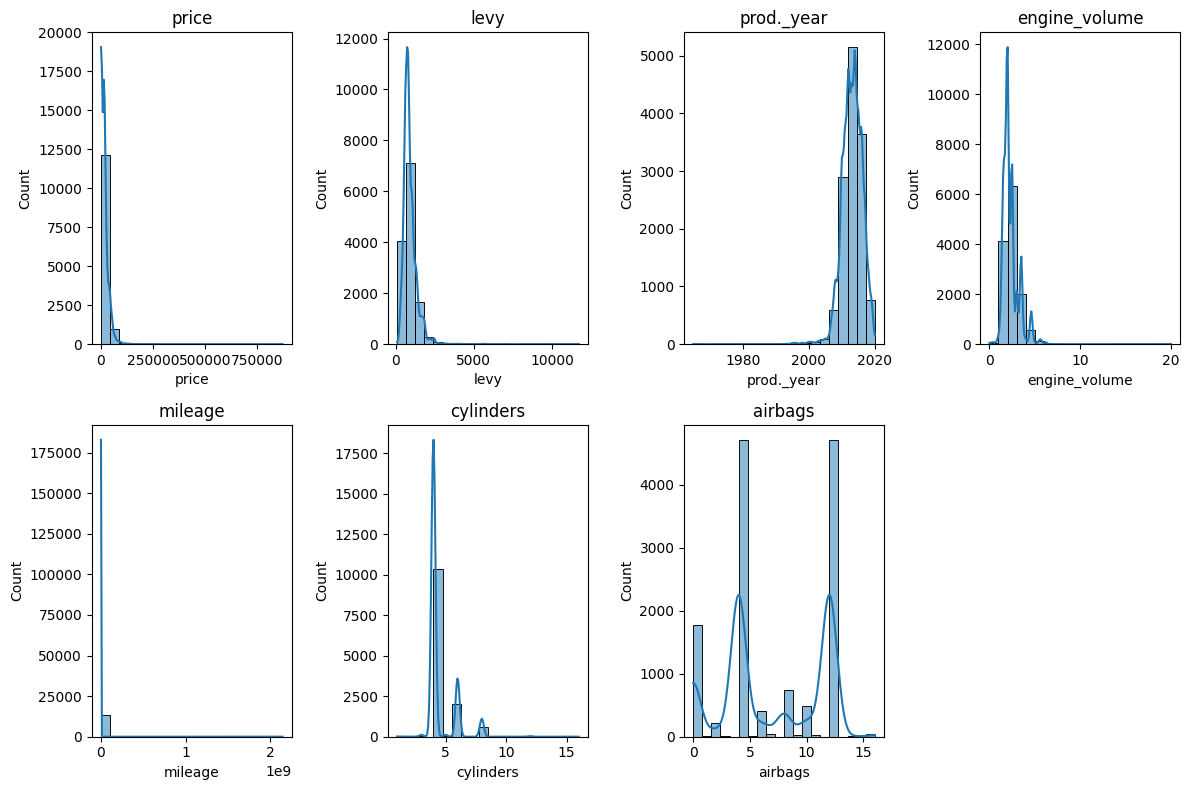

In [21]:
plt.figure(figsize=(12, 8))
for feature in num_features:
    plt.subplot(2, 4, num_features.index(feature) + 1)
    sns.histplot(data=df[feature], bins=20, kde=True)
    plt.title(feature)
plt.tight_layout()
plt.show()

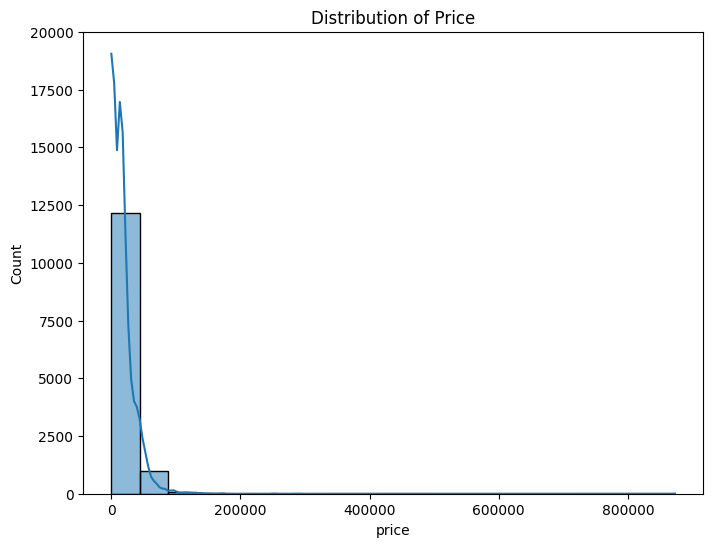

In [22]:
# Price Analysis
plt.figure(figsize=(8, 6))
sns.histplot(data=df['price'], bins=20, kde=True)
plt.title('Distribution of Price')
plt.show()

<Axes: xlabel='price', ylabel='Count'>

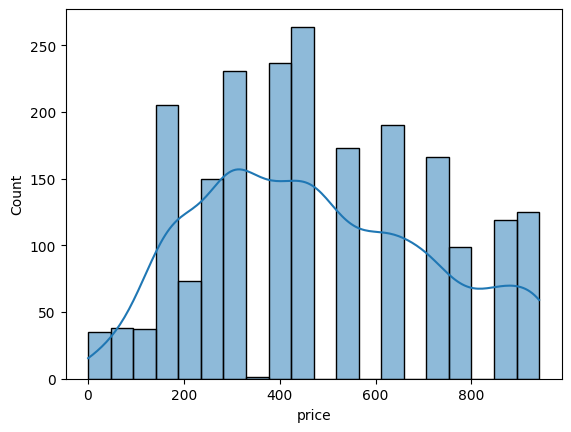

In [23]:
sns.histplot(df[df['price'] < 1000]['price'], bins=20, kde=True)

In [24]:
df[df["price"] < 1000][[
    "price", "prod._year", "mileage", "engine_volume", "manufacturer", "model"
]].describe()


,price,prod._year,mileage,engine_volume
count,2143.000000,2143.000000,2143.000000,2143.000000
mean,475.726085,2012.827811,169395.366309,2.682501
std,240.214974,2.885414,107842.486426,1.007454
min,1.000000,1996.000000,0.000000,0.000000
25%,282.000000,2011.000000,95349.000000,2.000000
50%,470.000000,2013.000000,158280.000000,2.500000
75%,627.000000,2015.000000,236403.000000,3.500000
max,941.000000,2020.000000,667058.000000,6.400000


In [ ]:
#we found that there are many cars with price less than 1000, which is not realistic. We will remove those rows from the dataset
df = df[df["price"] >= 1000].copy()

In [ ]:
#there are some cars with engine volume equal to 0, which is not realistic. We will remove those rows from the dataset
df = df[df["engine_volume"] > 0].copy()

the price column has a long right tail, we need to apply a logarithmic transformation

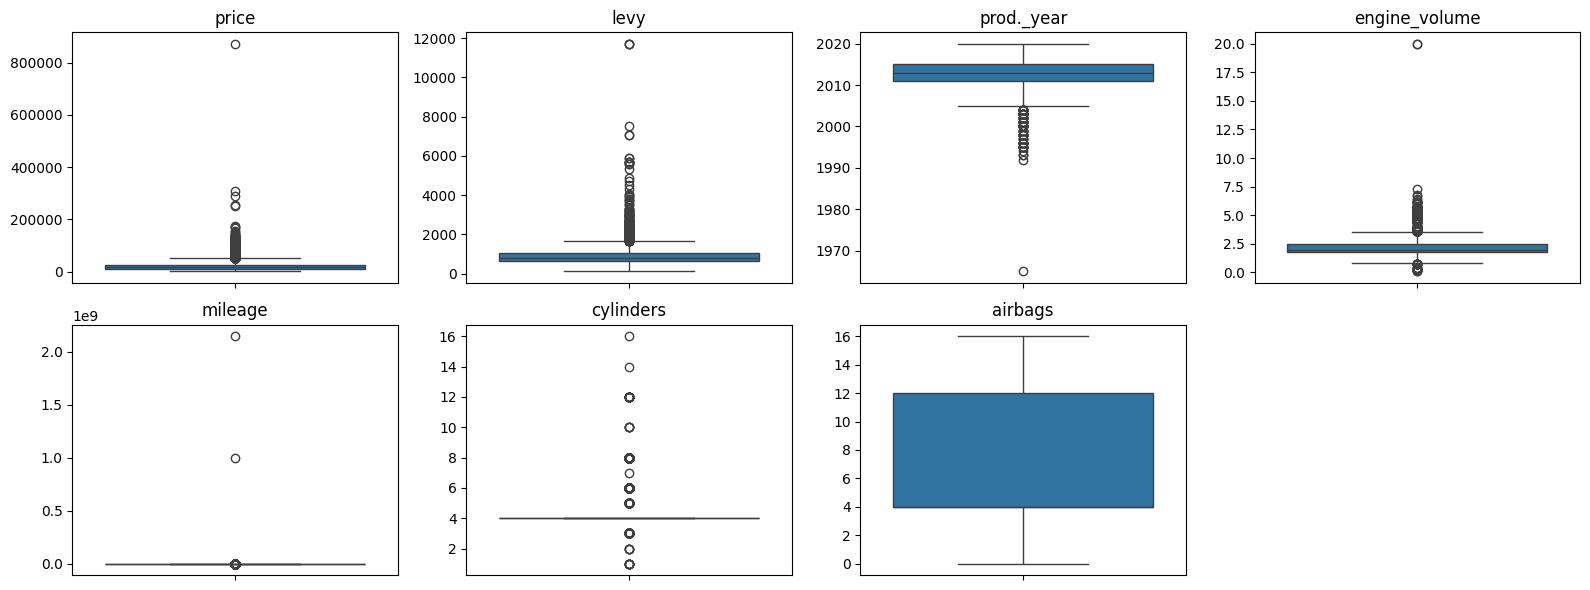

In [27]:
n = len(num_features)
cols = 4  # número de columnas en la grilla
rows = (n + cols - 1) // cols  # techo de n/cols

fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))
axes = axes.ravel()

for i, col in enumerate(num_features):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel("")

# Ocultar subplots vacíos si sobran
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Categorical Features

In [ ]:
categorical_features = df.select_dtypes(include="object").columns.tolist()
categorical_features.extend(["leather_interior", "turbo"]) 

In [29]:
for col in categorical_features:
    print(f"\n### {col} ###")
    print(df[col].value_counts(dropna=False))          # frecuencias
    print(df[col].value_counts(normalize=True, dropna=False))  # proporciones


### manufacturer ###
manufacturer
hyundai          3321
toyota           2010
chevrolet         883
mercedes-benz     784
ford              564
lexus             537
honda             475
ssangyong         437
bmw               384
kia               312
volkswagen        247
nissan            243
subaru            116
audi              110
daewoo             90
jeep               85
opel               76
mitsubishi         62
mazda              60
dodge              42
fiat               38
jaguar             20
mini               20
porsche            17
suzuki             17
land_rover         16
chrysler           12
buick              12
gmc                12
renault            11
acura              10
cadillac            8
infiniti            6
citroen             5
lincoln             3
volvo               3
vaz                 2
daihatsu            2
scion               2
ferrari             2
maserati            2
peugeot             2
mercury             2
bentley            

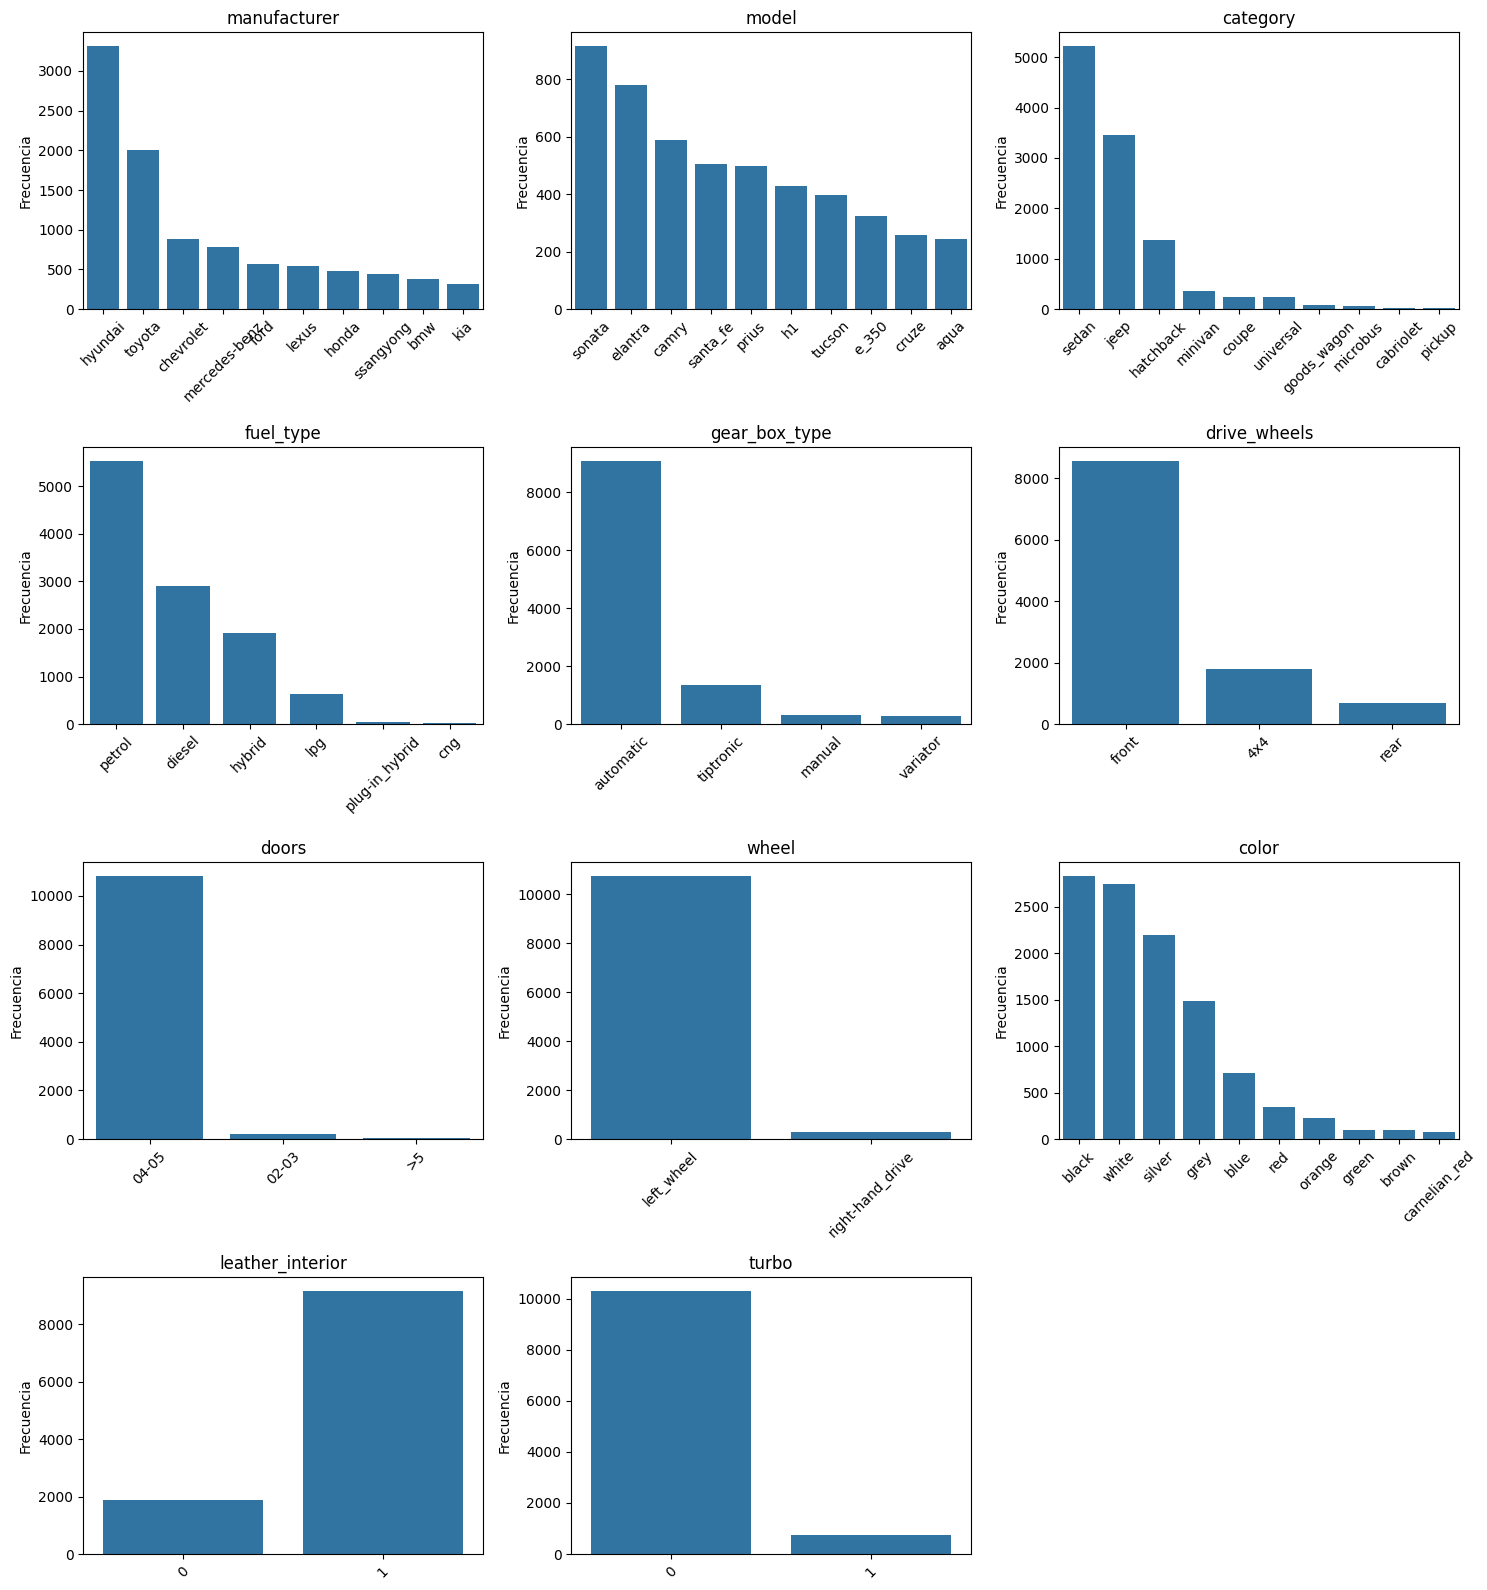

In [30]:

n = len(categorical_features)
cols = 3
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
axes = axes.ravel()

for i, col in enumerate(categorical_features):
    counts = df[col].value_counts(dropna=False)
    # Si hay muchas categorías, muestra solo las top N
    if len(counts) > 10:
        counts = counts.head(10)
    sns.barplot(x=counts.index, y=counts.values, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia")
    axes[i].tick_params(axis="x", rotation=45)

# Ocultar subplots vacíos
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

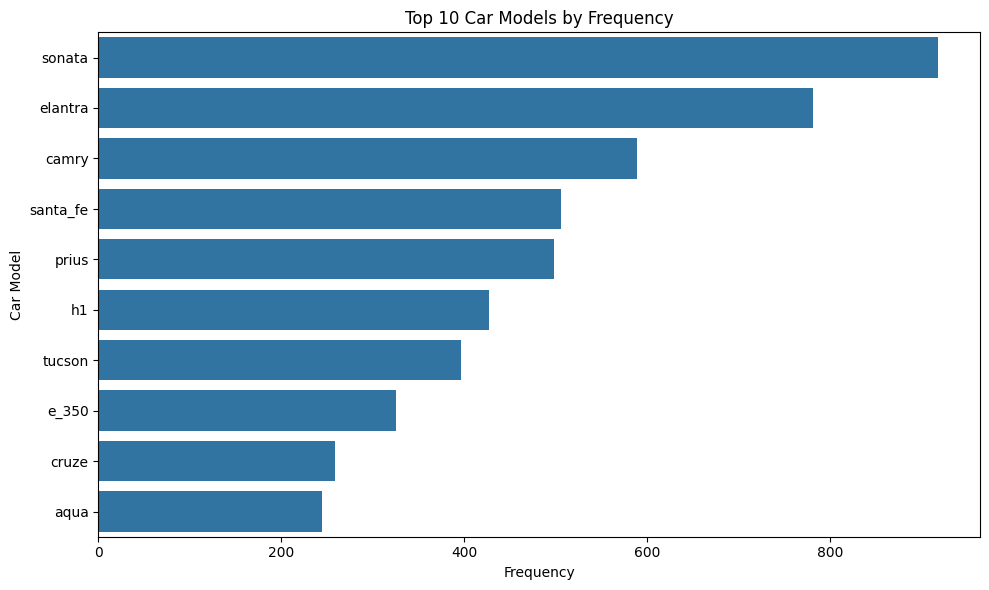

In [31]:
#Top 10 cars
n = 10  # Number of top car models to plot
top_car_models = df['model'].value_counts().head(n)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_car_models.values, y=top_car_models.index)
plt.title(f'Top {n} Car Models by Frequency')
plt.xlabel('Frequency')
plt.ylabel('Car Model')
plt.tight_layout()
plt.show()

## Bivariate Analysis

In [32]:
#Categorical vs Price Analysis

for col in categorical_features:
    print(f"\n### {col} vs price ###")
    stats = df.groupby(col, dropna=False)["price"].agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    print(stats.sort_values("mean", ascending=False))


### manufacturer vs price ###
               count          mean        median          std     min     max
manufacturer                                                                 
lamborghini        1 872946.000000 872946.000000          NaN  872946  872946
bentley            1 175622.000000 175622.000000          NaN  175622  175622
land_rover        16  78794.625000  72914.500000 44740.431161    9722  167781
ferrari            2  66955.500000  66955.500000 49451.512742   31988  101923
skoda              1  46101.000000  46101.000000          NaN   46101   46101
porsche           17  44652.588235  25716.000000 71848.042885    1176  308906
ssangyong        437  30904.700229  30596.000000 12071.390201    4077   61521
jeep              85  30497.588235  28821.000000 21513.589855    1019  147397
jaguar            20  28239.300000  32954.000000 19305.684072    1646   58683
lexus            537  27988.666667  18817.000000 24226.243325    1019  133284
maserati           2  26813.50000

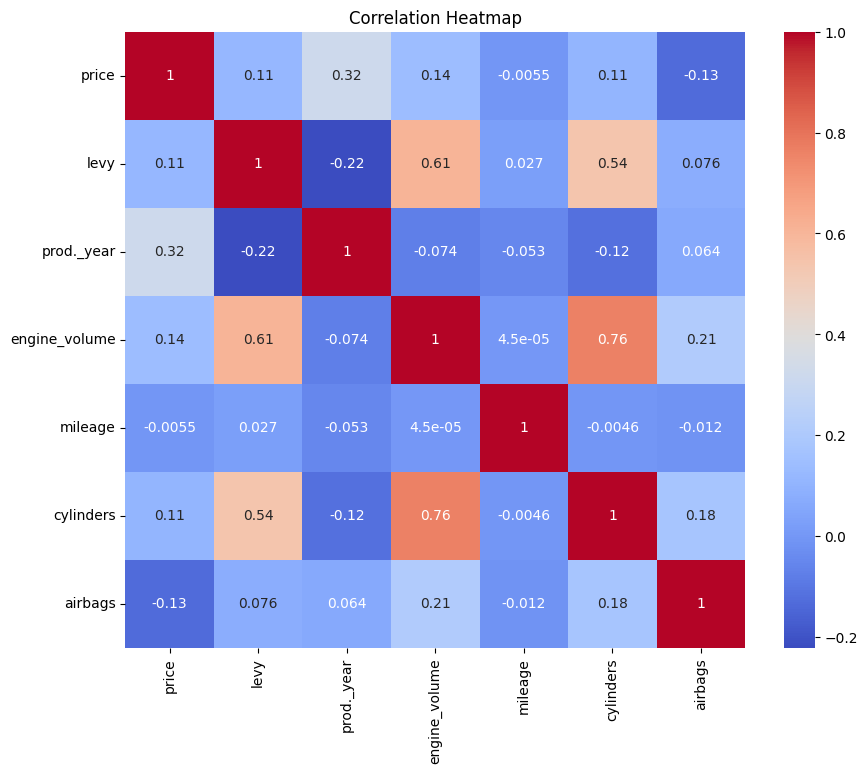

In [33]:
# Correlation Analysis
correlation_matrix = df[num_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()



# Train Model

In [ ]:
num_features.remove("price")

['levy', 'prod._year', 'engine_volume', 'mileage', 'cylinders', 'airbags']

In [40]:
df.head()

,id,price,levy,manufacturer,model,prod._year,category,leather_interior,fuel_type,engine_volume,mileage,cylinders,gear_box_type,drive_wheels,doors,wheel,color,airbags,turbo
0,45654403,13328,1399.000000,lexus,rx_450,2010,jeep,1,hybrid,3.500000,186005.000000,6.000000,automatic,4x4,04-05,left_wheel,silver,12,0
1,44731507,16621,1018.000000,chevrolet,equinox,2011,jeep,0,petrol,3.000000,192000.000000,6.000000,tiptronic,4x4,04-05,left_wheel,black,8,0
3,45769185,3607,862.000000,ford,escape,2011,jeep,1,hybrid,2.500000,168966.000000,4.000000,automatic,4x4,04-05,left_wheel,white,0,0
4,45809263,11726,446.000000,honda,fit,2014,hatchback,1,petrol,1.300000,91901.000000,4.000000,automatic,front,04-05,left_wheel,silver,4,0
5,45802912,39493,891.000000,hyundai,santa_fe,2016,jeep,1,diesel,2.000000,160931.000000,4.000000,automatic,front,04-05,left_wheel,white,4,0


In [41]:
X = df.drop(columns=["id","price"])
y = df["price"]

### Preprocessing Pipeline


In [42]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer,TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, PowerTransformer, TargetEncoder, OneHotEncoder



In [51]:
numeric_pipeline = Pipeline([
        ("scaler",StandardScaler())
])

categorical_pipeline = Pipeline([
    ('onehotencoder', OneHotEncoder(handle_unknown="ignore",drop='first'))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, num_features),
    ("categorical", categorical_pipeline, categorical_features)
], remainder="drop")

In [44]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.base import clone

In [45]:
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(),
    'XGB Regressor': XGBRegressor(n_estimators=200)
}

In [52]:
target_transformer = PowerTransformer(method='yeo-johnson', standardize=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

results = []

for name, model in models.items():
    transformed_clone = clone(target_transformer)
    ttr = TransformedTargetRegressor(regressor=model, transformer=transformed_clone)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", ttr)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "R-squared": r2
    })

results_df = pd.DataFrame(results).sort_values(by="RMSE", ascending=True)
print(results_df)



/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


              Model         RMSE  R-squared
3     XGB Regressor  8050.320242   0.779591
2     Decision Tree 10123.147886   0.651475
1             Ridge 11694.107088   0.534910
0  LinearRegression 11905.720839   0.517925


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
